# Who gets under-rated? A simple model of the PFA Team of the Year

**The idea.** Every year, the players vote for a PFA Team of the Year. If we learn what the voters usually reward,
we can ask, for any midfielder's season: *how likely was a player with these numbers to be picked?*
Add those probabilities up over a career and you get **expected selections**. Compare them with the **actual**
selections:
- more actual than expected = recognised **more** than his numbers suggest;
- fewer actual than expected = **under-rated** by the voters' own standards.

**The model.** A logistic regression on the six per-90 dimensions from notebook 01 (as percentiles within each
season) plus minutes played. Each season's probabilities come from a model trained on the *other* seven seasons,
so no player is judged by a model that has already seen his own selection.

**Data.** Opta, 2010/11 to 2017/18, midfielders with 1,800+ minutes (617 seasons, 30 selections).
Checked against Understat (xG-based numbers), 2014/15 to 2020/21.

In [1]:
from pathlib import Path
import html

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project folder
REPO = next(p for p in [ROOT, *ROOT.parents] if (p / "src" / "football_analytics").exists())  # repo root
U = REPO / "data" / "raw" / "understat"
EXT = ROOT / "data" / "external"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

SKY, NAVY, GREY, DARK, MUTED, LIGHT, GOLD = "#6CABDD", "#1C2C5B", "#B4B2A9", "#2B2B2A", "#6B6A64", "#F4F2EE", "#C9A227"
SRC_PL = "Data: Premier League official stats (Opta), premierleague.com. Midfielders as listed in each club's squad"
SRC_U = "Data: Understat (via douglasbc/scraping-understat-dataset)"
for _f in (ROOT / "assets" / "fonts").glob("*.ttf"):  # Barlow, bundled with the project (SIL Open Font License)
    font_manager.fontManager.addfont(str(_f))
plt.rcParams.update({
    "font.family": "Barlow", "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
})


def titles(fig, title, subtitle, source, y=1.06):
    fig.suptitle(title, x=0.01, y=y, ha="left", va="bottom", fontsize=17, fontweight="bold", color=DARK, family="Barlow Condensed")
    fig.text(0.01, y - 0.005, subtitle, ha="left", va="top", fontsize=10.5, color=MUTED)
    fig.text(0.01, -0.03, source, ha="left", va="top", fontsize=8, color=MUTED)


def season_label(s):
    """2013 -> '2013/14'"""
    return f"{s}/{str(s + 1)[-2:]}"


def load_opta(min_minutes=0):
    """Every Premier League midfielder, 2010/11 to 2017/18 (official Opta stats)."""
    d = pd.read_csv(EXT / "pl_midfielders_2010-2018.csv")
    d = d[d.timePlayed >= min_minutes].copy()
    p90 = lambda s: s / d.timePlayed * 90
    d["npg"] = d.goals - d.penaltyGoals
    d["scoring"] = p90(d.npg)                                   # non-penalty goals per 90
    d["assisting"] = p90(d.goalAssists)                         # assists per 90
    d["creating"] = p90(d.keyPassesAttemptAssists)              # chances created per 90
    d["passing"] = p90(d.successfulPassesOppositionHalf)        # completed passes in the opposition half per 90
    d["carrying"] = p90(d.successfulDribbles)                   # successful dribbles per 90
    d["defending"] = p90(d.tacklesWon + d.interceptions)        # tackles won + interceptions per 90
    d["passes90"] = p90(d.totalPasses)
    d["pass_pct"] = 1 - d.totalUnsuccessfulPassesExclCrossesAndCorners / d.totalPasses
    return d


DIMS = ["scoring", "assisting", "creating", "passing", "carrying", "defending"]
DIM_LABELS = {"scoring": "Scoring\n(non-penalty goals)", "assisting": "Assisting\n(assists)", "creating": "Creating\n(chances created)",
              "passing": "Passing\n(passes in opp. half)", "carrying": "Carrying\n(successful dribbles)",
              "defending": "Defending\n(tackles won + interceptions)"}
YAYA = "Yaya Touré"

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_predict

M = load_opta(min_minutes=1800)
for c in DIMS:
    M["p_" + c] = M.groupby("season")[c].rank(pct=True)
M["p_minutes"] = M.groupby("season").timePlayed.rank(pct=True)
T = pd.read_csv(EXT / "pfa_team_of_the_year.csv")
T["start"] = T.season.str[:4].astype(int)
picked = set(zip(T.start, T.player))
M["toty"] = [(s, n) in picked for s, n in zip(M.season, M.name)]
FEATS = ["p_" + c for c in DIMS] + ["p_minutes"]
model = LogisticRegression(max_iter=2000)
M["prob"] = cross_val_predict(model, M[FEATS], M.toty, groups=M.season, cv=GroupKFold(8), method="predict_proba")[:, 1]
model.fit(M[FEATS], M.toty)
COEF = pd.Series(model.coef_[0], index=FEATS)
print(f"{len(M)} seasons, {M.toty.sum()} selections; held-out AUC {roc_auc_score(M.toty, M.prob):.2f}")
COEF.round(2)

617 seasons, 30 selections; held-out AUC 0.86


p_scoring      1.55
p_assisting    1.02
p_creating     0.35
p_passing      1.49
p_carrying     1.74
p_defending    0.03
p_minutes      2.27
dtype: float64

In [3]:
CAREER = M.groupby("id").agg(name=("name", "last"), seasons=("season", "size"), expected=("prob", "sum"), actual=("toty", "sum"))
CAREER["gap"] = CAREER.actual - CAREER.expected
CAREER.sort_values("gap").head(10).round(2)

,name,seasons,expected,actual,gap
id,,,,,
19524,Santiago Cazorla,3,0.87,0,-0.87
37605,Mesut Özil,5,0.86,0,-0.86
88894,Ross Barkley,4,0.57,0,-0.57
17878,Cesc Fàbregas,4,0.37,0,-0.37
12002,Stewart Downing,6,0.35,0,-0.35
34392,Stéphane Sessegnon,3,0.33,0,-0.33
41792,Aaron Ramsey,5,0.32,0,-0.32
74208,Paul Pogba,2,0.32,0,-0.32
37055,Luka Modric,2,0.32,0,-0.32


In [4]:
CAREER.sort_values("gap", ascending=False).head(8).round(2)

,name,seasons,expected,actual,gap
id,,,,,
42786,Eden Hazard,5,1.51,4,2.49
36903,Gareth Bale,3,0.52,3,2.48
116594,N'Golo Kanté,3,0.11,2,1.89
108823,Dele Alli,3,0.38,2,1.62
14664,Yaya Touré,7,1.01,2,0.99
2404,Michael Carrick,5,0.06,1,0.94
1411,Scott Parker,3,0.07,1,0.93
54102,Jack Wilshere,2,0.08,1,0.92


In [5]:
M[M.name == YAYA][["season", "prob", "toty"] + ["p_" + c for c in DIMS]].round(2)

,season,prob,toty,p_scoring,p_assisting,p_creating,p_passing,p_carrying,p_defending
73,2010,0.17,False,0.84,0.57,0.34,0.79,0.76,0.12
263,2011,0.18,True,0.84,0.80,0.66,0.97,0.78,0.42
451,2012,0.17,False,0.87,0.69,0.56,0.96,0.75,0.14
640,2013,0.24,True,1.00,0.92,0.38,0.95,0.70,0.17
842,2014,0.11,False,0.95,0.25,0.52,1.00,0.78,0.06
1030,2015,0.12,False,0.81,0.70,0.65,0.94,0.84,0.23
1242,2016,0.01,False,0.61,0.09,0.34,0.95,0.66,0.34


## Charts

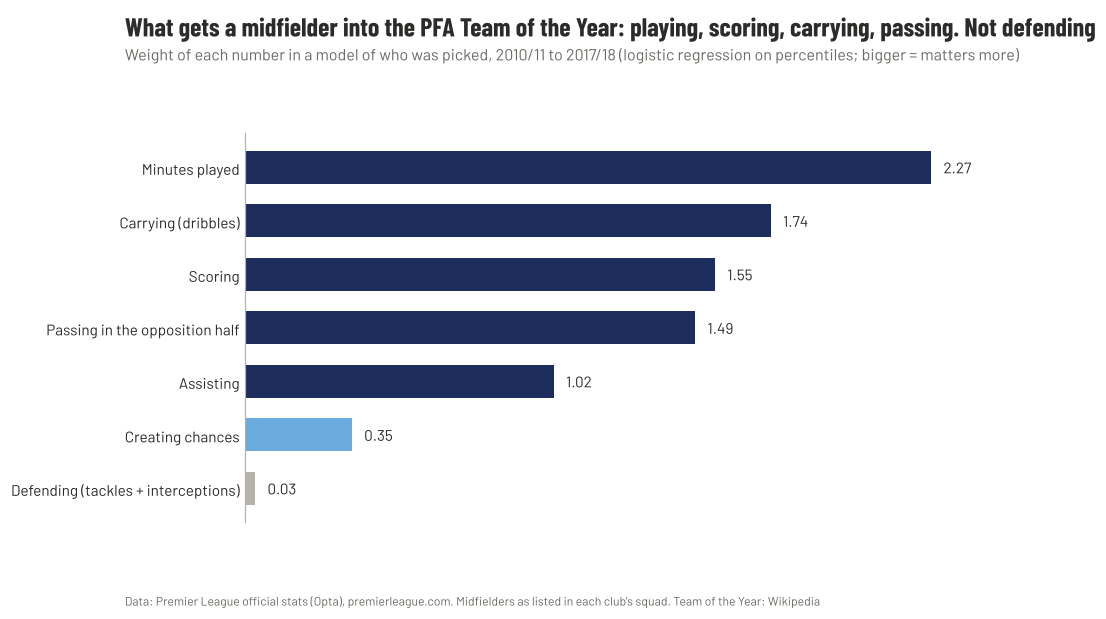

In [6]:
# Figure 6: what the voters reward
lab = {"p_scoring": "Scoring", "p_assisting": "Assisting", "p_creating": "Creating chances", "p_passing": "Passing in the opposition half",
       "p_carrying": "Carrying (dribbles)", "p_defending": "Defending (tackles + interceptions)", "p_minutes": "Minutes played"}
c = COEF.sort_values()
fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.barh(range(len(c)), c.values, color=[NAVY if v >= 1 else SKY if v >= 0.3 else GREY for v in c.values], height=0.62)
for i, v in enumerate(c.values):
    ax.text(v + 0.04, i, f"{v:.2f}", va="center", fontsize=10, color=DARK)
ax.set_yticks(range(len(c)), [lab[k] for k in c.index], fontsize=10)
ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.set_xlim(0, c.max() * 1.18)
titles(fig, "What gets a midfielder into the PFA Team of the Year: playing, scoring, carrying, passing. Not defending",
       "Weight of each number in a model of who was picked, 2010/11 to 2017/18 (logistic regression on percentiles; bigger = matters more)",
       SRC_PL + ". Team of the Year: Wikipedia")
fig.savefig(FIGS / "06_what_voters_reward.png")

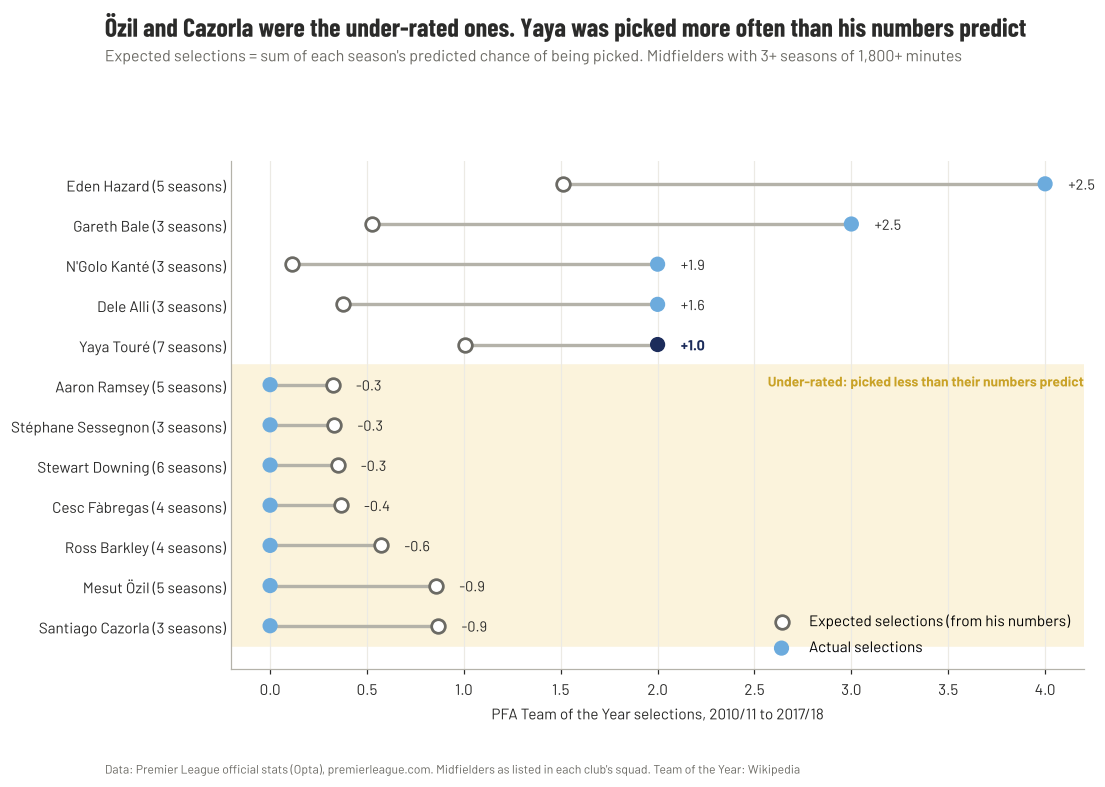

In [7]:
# Figure 7: expected vs actual selections
sub = CAREER[CAREER.seasons >= 3]
show = pd.concat([sub.sort_values("gap").head(7), sub.sort_values("gap", ascending=False).head(5)]).drop_duplicates()
if YAYA not in show.name.values:
    show = pd.concat([show, sub[sub.name == YAYA]])
show = show.sort_values("gap")
fig, ax = plt.subplots(figsize=(10, 6))
yy = np.arange(len(show))
for yi, r in zip(yy, show.itertuples()):
    ax.plot([r.expected, r.actual], [yi, yi], color=GREY, lw=2.2, zorder=1)
ax.scatter(show.expected, yy, s=80, color="white", edgecolors=MUTED, lw=1.8, zorder=2, label="Expected selections (from his numbers)")
ax.scatter(show.actual, yy, s=80, color=[NAVY if n == YAYA else SKY for n in show.name], zorder=3, label="Actual selections")
for yi, r in zip(yy, show.itertuples()):
    ax.text(max(r.expected, r.actual) + 0.12, yi, f"{r.gap:+.1f}", va="center", fontsize=9.5,
            color=NAVY if r.name == YAYA else DARK, fontweight="bold" if r.name == YAYA else "normal")
ax.set_yticks(yy, [f"{r.name} ({r.seasons} seasons)" for r in show.itertuples()], fontsize=10)
ax.set_xlabel("PFA Team of the Year selections, 2010/11 to 2017/18"); ax.grid(axis="x", color="#ECEAE4"); ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0); ax.legend(frameon=False, loc="lower right")
ax.axhspan(-0.5, (show.gap < 0).sum() - 0.5, color="#FBF3DC", zorder=0)
ax.text(ax.get_xlim()[1], (show.gap < 0).sum() - 0.7, "Under-rated: picked less than their numbers predict", ha="right", va="top", fontsize=9, color=GOLD, fontweight="bold")
titles(fig, "Özil and Cazorla were the under-rated ones. Yaya was picked more often than his numbers predict",
       "Expected selections = sum of each season's predicted chance of being picked. Midfielders with 3+ seasons of 1,800+ minutes",
       SRC_PL + ". Team of the Year: Wikipedia")
fig.savefig(FIGS / "07_expected_vs_actual_selections.png")

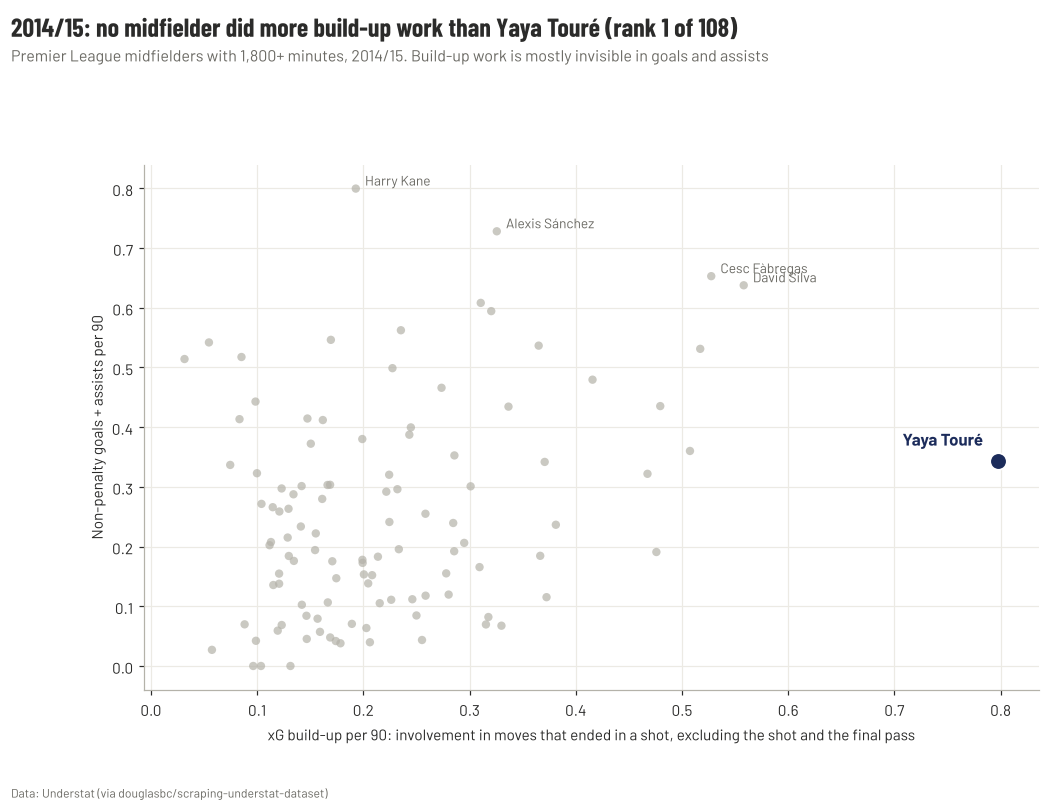

In [8]:
# Figure 8: Understat check — the build-up work voters don't see (2014/15)
UP = pd.concat([pd.read_csv(U / f"players_epl_{y}-{y + 1}.csv").assign(start=2000 + y) for y in range(14, 21)])
UP["player_name"] = UP.player_name.map(html.unescape)
UM = UP[UP.position.str.contains("M") & (UP.time >= 1800)].copy()
for c in ["npxG", "xA", "xGBuildup", "npg", "assists"]:
    UM[c + "90"] = UM[c] / UM.time * 90
UM["ga90"] = UM.npg90 + UM.assists90
s14 = UM[UM.start == 2014]
fig, ax = plt.subplots(figsize=(10.5, 6.2))
ax.scatter(s14.xGBuildup90, s14.ga90, s=30, color=GREY, alpha=0.7, edgecolors="none")
yr = s14[s14.player_name == YAYA].iloc[0]
ax.scatter(yr.xGBuildup90, yr.ga90, s=120, color=NAVY, edgecolors="white", lw=1.2, zorder=3)
ax.annotate("Yaya Touré", (yr.xGBuildup90, yr.ga90), xytext=(-10, 10), textcoords="offset points", ha="right", fontsize=11, color=NAVY, fontweight="bold")
for r in s14.sort_values("ga90", ascending=False).head(4).itertuples():
    ax.annotate(r.player_name, (r.xGBuildup90, r.ga90), xytext=(6, 2), textcoords="offset points", fontsize=9, color=MUTED)
rank = int(s14.xGBuildup90.rank(ascending=False)[s14.player_name == YAYA].iloc[0])
ax.set_xlabel("xG build-up per 90: involvement in moves that ended in a shot, excluding the shot and the final pass")
ax.set_ylabel("Non-penalty goals + assists per 90"); ax.grid(color="#ECEAE4", lw=0.8); ax.set_axisbelow(True)
titles(fig, f"2014/15: no midfielder did more build-up work than Yaya Touré (rank {rank} of {len(s14)})",
       "Premier League midfielders with 1,800+ minutes, 2014/15. Build-up work is mostly invisible in goals and assists",
       SRC_U)
fig.savefig(FIGS / "08_buildup_2014_15.png")

In [9]:
# The same model on Understat numbers, 2014/15 to 2020/21 (a check, not a chart)
UDIMS = ["npg90", "assists90", "npxG90", "xA90", "xGBuildup90"]
for c in UDIMS:
    UM["p_" + c] = UM.groupby("start")[c].rank(pct=True)
UM["p_min"] = UM.groupby("start").time.rank(pct=True)
alias = {"İlkay Gündoğan": "Ilkay Gündogan", "Thiago": "Thiago Alcántara"}
upicked = {(s, alias.get(n, n)) for s, n in picked}
UM["toty"] = [(s, n) in upicked for s, n in zip(UM.start, UM.player_name)]
UF = ["p_" + c for c in UDIMS] + ["p_min"]
UM["prob"] = cross_val_predict(LogisticRegression(max_iter=2000), UM[UF], UM.toty, groups=UM.start, cv=GroupKFold(7), method="predict_proba")[:, 1]
UC = UM.groupby("player_name").agg(seasons=("start", "size"), expected=("prob", "sum"), actual=("toty", "sum"))
UC["gap"] = UC.actual - UC.expected
print(f"Understat check: {len(UM)} seasons, {UM.toty.sum()} selections, held-out AUC {roc_auc_score(UM.toty, UM.prob):.2f}")
UC.sort_values("gap").head(8).round(2)

Understat check: 754 seasons, 29 selections, held-out AUC 0.91


,seasons,expected,actual,gap
player_name,,,,
Roberto Firmino,5,0.93,0,-0.93
Mesut Özil,4,0.88,0,-0.88
Gylfi Sigurdsson,7,0.39,0,-0.39
Ross Barkley,3,0.37,0,-0.37
Aaron Ramsey,3,0.36,0,-0.36
Cesc Fàbregas,3,0.35,0,-0.35
Georginio Wijnaldum,6,0.34,0,-0.34
Leroy Sané,2,0.34,0,-0.34
